Index(['id', 'state', 'rto', 'maker', 'count'], dtype='str')
                         state                 rto   count
0     Andaman & Nicobar Island      Port Blair DTO  190689
1               Andhra Pradesh           Adoni RTO  263708
2               Andhra Pradesh      Amalapuram RTA  278026
3               Andhra Pradesh      Anakapalli RTA  575922
4               Andhra Pradesh       Anantapur RTA  653369
...                        ...                 ...     ...
1451               West Bengal      SRIRAMPUR ARTO  238030
1452               West Bengal          TAMLUK RTO  439756
1453               West Bengal        TEHATTA ARTO   12020
1454               West Bengal       ULUBERIA ARTO  239232
1455               West Bengal  UTTAR DINAJPUR RTO  340288

[1456 rows x 3 columns]
53352.25 412255.75
-485003.0 950611.0
               state                                 rto    count
23    Andhra Pradesh                          Guntur RTA  1086197
81    Andhra Pradesh                

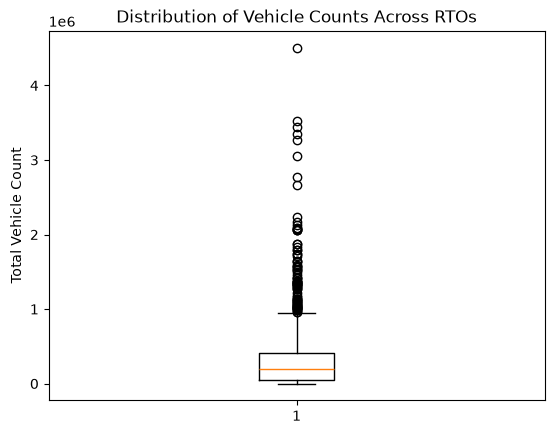

Median: 189326.5


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv("vehicle.csv")  
print(df.columns)
duplicate= df[df.duplicated(["state","rto","maker"], keep=False)]

repeat=df[df.duplicated(["id"],keep=False)]

res=df.groupby(["state", "rto"],as_index=False)["count"].sum()
print(res)
q1=res["count"].quantile(0.25)
q3=res["count"].quantile(0.75)
print(q1,q3)
IQR=q3-q1
lower=q1-(1.5*IQR)
upper=q3+(1.5*IQR)  
print(lower,upper)
outliers = res[
    (res["count"] < lower) |
    (res["count"] > upper)
]

percentage = (len(outliers) / len(res)) * 100
print(outliers,percentage)
outliers.sort_values(
    by="count",
    ascending=False
)[["state", "rto", "count"]].head(10)
plt.boxplot(res["count"])

plt.title("Distribution of Vehicle Counts Across RTOs")
plt.ylabel("Total Vehicle Count")

plt.show()
median_value = res["count"].median()
print("Median:", median_value)

Top 5 RTOs:
               state                                 rto    count
777      Maharashtra                                PUNE  4508411
709   Madhya Pradesh                          INDORE RTO  3518618
1045       Rajasthan                  JAIPUR (FIRST) RTO  3441478
1377   Uttar Pradesh  TRANSPORT NAGAR RTO LUCKNOW (UP32)  3352632
270          Gujarat                               SURAT  3274200

Number of observations per RTO:
rto
INDORE RTO                            393
JAIPUR (FIRST) RTO                    266
PUNE                                  444
SURAT                                 370
TRANSPORT NAGAR RTO LUCKNOW (UP32)    477
Name: count, dtype: int64


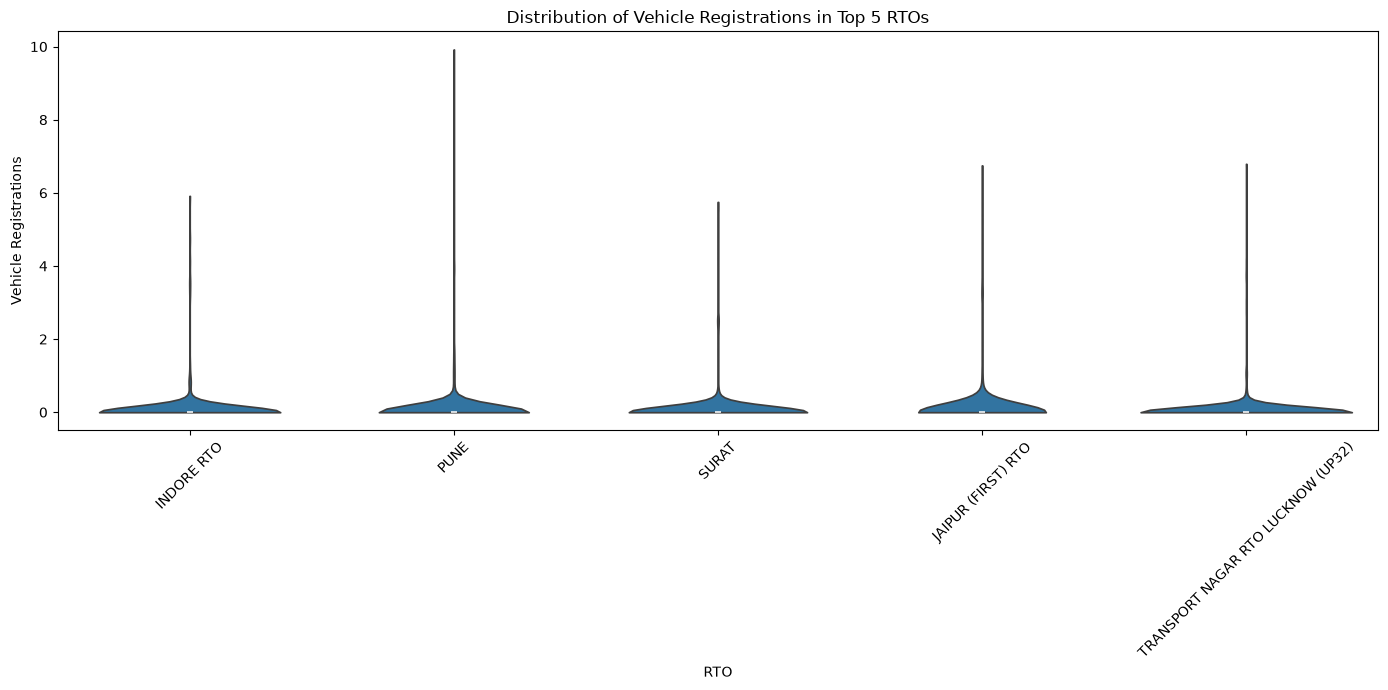

Unique manufacturers: 393


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Load the dataset
df = pd.read_csv("vehicle.csv")

# Step 2: Group by State and RTO
data = df.groupby(
    ["state", "rto"],
    as_index=False
)["count"].sum()

# Step 3: Sort by total registrations
data = data.sort_values(
    by="count",
    ascending=False
)

# Step 4: Select top 5 RTOs
top5 = data.head(5)

print("Top 5 RTOs:")
print(top5)

# Step 5: Filter original dataset for those 5 RTOs
top5_data = df.merge(
    top5[["state", "rto"]],
    on=["state", "rto"],
    how="inner"
)

# Step 6: Check number of observations per RTO
print("\nNumber of observations per RTO:")
print(top5_data.groupby("rto")["count"].count())

# Step 7: Create violin plot
plt.figure(figsize=(14, 7))
top5_data["count_lakhs"] = top5_data["count"] / 100000
sns.violinplot(
    data=top5_data,
    x="rto",
    y="count_lakhs",
    inner="box",
    cut=0
)

plt.title("Distribution of Vehicle Registrations in Top 5 RTOs")
plt.xlabel("RTO")
plt.ylabel("Vehicle Registrations")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()
indore = top5_data[top5_data["rto"] == "INDORE RTO"]

print("Unique manufacturers:", indore["maker"].nunique())

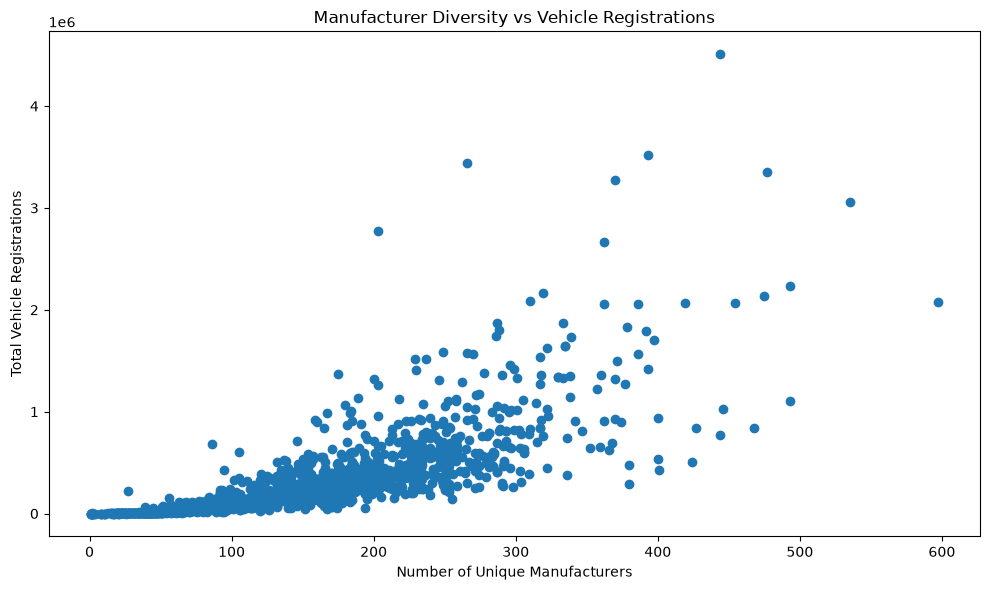

                      Unique_Manufacturers  Total_Vehicles
Unique_Manufacturers              1.000000        0.763937
Total_Vehicles                    0.763937        1.000000


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("vehicle.csv")

rto_analysis = df.groupby(
    ["state", "rto"],
    as_index=False
).agg(
    Total_Vehicles=("count", "sum"),
    Unique_Manufacturers=("maker", "nunique")
)
diversity = rto_analysis.sort_values(
    by="Unique_Manufacturers",
    ascending=False
)
plt.figure(figsize=(10, 6))

plt.scatter(
    rto_analysis["Unique_Manufacturers"],
    rto_analysis["Total_Vehicles"]
)

plt.title("Manufacturer Diversity vs Vehicle Registrations")
plt.xlabel("Number of Unique Manufacturers")
plt.ylabel("Total Vehicle Registrations")

plt.tight_layout()
plt.show()
correlation = rto_analysis[
    ["Unique_Manufacturers", "Total_Vehicles"]
].corr()

print(correlation)